# Exploración del dataset Food.com — Social Graphs 02805

Objetivo: **tocar los datos antes de elegir la pregunta**. El notebook responde a:

1. ¿Cuántos usuarios, recetas e interacciones hay realmente?
2. ¿Cuántas reviews tienen texto y qué longitud tienen?
3. ¿Qué pinta tiene la red bipartita usuario–receta?
4. ¿Hay estructura de comunidades que valga la pena (frente a un modelo nulo)?
5. ¿El texto de las reviews contiene información útil?

Además hace una **prueba rápida de las tres ideas** (comunidades de usuarios y lenguaje, similitud de ingredientes y de opiniones, recetas puente).

**Cómo usarlo**
- Descarga de Kaggle *"Food.com Recipes and User Interactions"* (shuyangli94/food-com-recipes-and-user-interactions) los ficheros `RAW_recipes.csv` y `RAW_interactions.csv`, y ponlos en una carpeta `data/` junto al notebook.
- Ejecuta de arriba abajo (*Run All*). Tarda unos minutos; las partes más lentas son el modelo nulo y la betweenness.
- La última celda imprime un **resumen con todos los números clave**: cópialo y pégamelo para decidir la pregunta.

Los cuadros **👀 Qué mirar** te dicen qué interpretar en cada paso.

In [1]:
import os, ast, json, random, time, warnings
from collections import Counter
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import spearmanr
from sklearn.metrics import normalized_mutual_info_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
warnings.filterwarnings("ignore")

DATA_DIR = "data"     # carpeta con RAW_recipes.csv y RAW_interactions.csv
FIG_DIR = "figs"      # aquí se guardan las figuras
SEED = 42
os.makedirs(FIG_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)
random.seed(SEED)
SUMMARY = {}          # aquí vamos guardando los números clave

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150)
    plt.show()

def ccdf(values, label, ax):
    v = np.sort(np.asarray(values))
    y = 1.0 - np.arange(len(v)) / len(v)
    ax.loglog(v, y, marker=".", linestyle="none", markersize=3, label=label)

## 1. Carga y números básicos

In [2]:
def parse_list(s):
    try:
        return ast.literal_eval(s) if isinstance(s, str) else []
    except (ValueError, SyntaxError):
        return []

t0 = time.time()
recipes = pd.read_csv(f"{DATA_DIR}/RAW_recipes.csv")
inter = pd.read_csv(f"{DATA_DIR}/RAW_interactions.csv")
for col in ["tags", "ingredients", "steps"]:
    recipes[col] = recipes[col].apply(parse_list)
inter["date"] = pd.to_datetime(inter["date"], errors="coerce")
inter["review"] = inter["review"].fillna("").astype(str)
print(f"Cargado en {time.time()-t0:.0f}s")
print(recipes.columns.tolist())
print(inter.columns.tolist())
recipes.head(2)

Cargado en 83s
['name', 'id', 'minutes', 'contributor_id', 'submitted', 'tags', 'nutrition', 'n_steps', 'steps', 'description', 'ingredients', 'n_ingredients']
['user_id', 'recipe_id', 'date', 'rating', 'review']


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"[60-minutes-or-less, time-to-make, course, mai...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"[make a choice and proceed with recipe, depend...",autumn is my favorite time of year to cook! th...,"[winter squash, mexican seasoning, mixed spice...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"[30-minutes-or-less, time-to-make, course, mai...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"[preheat oven to 425 degrees f, press dough in...",this recipe calls for the crust to be prebaked...,"[prepared pizza crust, sausage patty, eggs, mi...",6


n_recipes                           231637
n_users                             226570
n_interactions                      1132367
n_recipes_with_any_interaction      231637
interactions_recipe_missing         0
duplicate_user_recipe_pairs         0
date_range                          ['2000-01-25', '2018-12-20']
rating_share                        {0: 0.054, 1: 0.011, 2: 0.012, 3: 0.036, 4: 0.165, 5: 0.721}


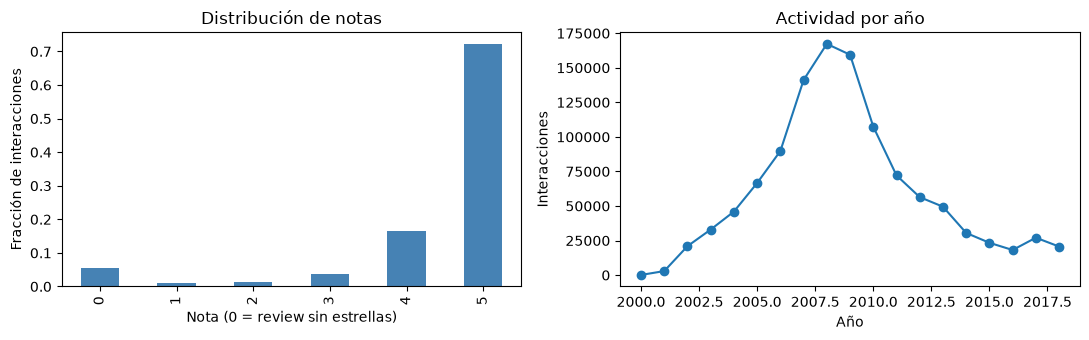

In [3]:
SUMMARY["n_recipes"] = int(recipes["id"].nunique())
SUMMARY["n_users"] = int(inter["user_id"].nunique())
SUMMARY["n_interactions"] = int(len(inter))
SUMMARY["n_recipes_with_any_interaction"] = int(inter["recipe_id"].nunique())
SUMMARY["interactions_recipe_missing"] = int((~inter["recipe_id"].isin(recipes["id"])).sum())
SUMMARY["duplicate_user_recipe_pairs"] = int(inter.duplicated(["user_id", "recipe_id"]).sum())
SUMMARY["date_range"] = [str(inter["date"].min().date()), str(inter["date"].max().date())]
rating_share = inter["rating"].value_counts(normalize=True).sort_index()
SUMMARY["rating_share"] = {int(k): round(float(v), 3) for k, v in rating_share.items()}
for k, v in SUMMARY.items():
    print(f"{k:35s} {v}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
rating_share.plot.bar(ax=axes[0], color="steelblue")
axes[0].set_xlabel("Nota (0 = review sin estrellas)"); axes[0].set_ylabel("Fracción de interacciones")
axes[0].set_title("Distribución de notas")
inter.groupby(inter["date"].dt.year).size().plot(ax=axes[1], marker="o")
axes[1].set_xlabel("Año"); axes[1].set_ylabel("Interacciones"); axes[1].set_title("Actividad por año")
savefig("01_ratings_y_actividad")

👀 **Qué mirar:** el porcentaje de 5 estrellas (si es ~75 %, la nota sirve poco como variable) y la actividad por año (si casi todo está en 2008–2012, cualquier comunidad de usuarios puede ser en realidad "generación de usuarios").

## 2. Texto de las reviews

{'pct_reviews_with_text': np.float64(99.98), 'review_words_percentiles': {10: 16, 25: 27, 50: 44, 75: 67, 90: 96, 99: 182}, 'pct_reviews_under_10_words': np.float64(4.53), 'total_review_words_millions': np.float64(58.9)}

Longitud mediana por nota:
rating
0    37.0
1    38.0
2    43.0
3    48.0
4    47.0
5    44.0
Name: n_words, dtype: float64


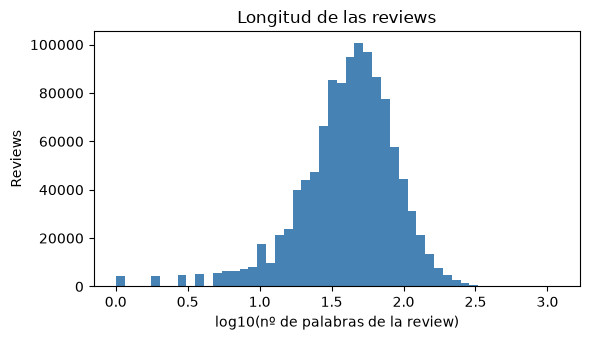

In [4]:
inter["n_words"] = inter["review"].str.split().str.len().fillna(0).astype(int)
has_text = inter["n_words"] > 0
SUMMARY["pct_reviews_with_text"] = round(100 * has_text.mean(), 2)
SUMMARY["review_words_percentiles"] = {
    p: int(np.percentile(inter.loc[has_text, "n_words"], p)) for p in [10, 25, 50, 75, 90, 99]}
SUMMARY["pct_reviews_under_10_words"] = round(100 * (inter.loc[has_text, "n_words"] < 10).mean(), 2)
SUMMARY["total_review_words_millions"] = round(inter["n_words"].sum() / 1e6, 1)
print({k: SUMMARY[k] for k in ["pct_reviews_with_text", "review_words_percentiles",
                               "pct_reviews_under_10_words", "total_review_words_millions"]})
print("\nLongitud mediana por nota:")
print(inter[has_text].groupby("rating")["n_words"].median())

plt.figure(figsize=(6, 3.5))
plt.hist(np.log10(inter.loc[has_text, "n_words"]), bins=50, color="steelblue")
plt.xlabel("log10(nº de palabras de la review)"); plt.ylabel("Reviews")
plt.title("Longitud de las reviews")
savefig("02_longitud_reviews")

In [5]:
# Lee de verdad unas cuantas reviews (el curso insiste: leer antes de fiarse de los números)
sample = inter[has_text].sample(15, random_state=SEED)
for _, row in sample.iterrows():
    print(f"[{row['rating']}★, {row['n_words']} palabras] {row['review'][:300]}\n")

[4★, 127 palabras] This is a very cute idea. I made this for DH with sandwiches last night. He thought I was nuts b4, now I've removed all doubt LOL. What a great way to get kids to eat salad BTW. You could also add some broccoli as trees or little bushes and if you have the patience you could cut raddishes, bell pepp

[5★, 78 palabras] Cake was AMAZING!! I found it reallyyy moist and good. It wasn't all too sweet in the end, so I'm glad for that because too much sweetness can ruin my sweet tooth. I put a bit too much vinegar by accident, but that didn't change anything. I loooved this. I'm also planning to share this with my frien

[4★, 42 palabras] I let this sit all day on high and it worked out great.  Added a small can of tomato paste and served with a glob of sour cream.  Everyone loved it!  I agree with Kris, you could add about anything to it.

[5★, 35 palabras] This recipe was fantastic. Very easy and the cooked apples made it seem like we had warm, homemade apple sauce with t

👀 **Qué mirar:** ¿hablan de **la receta** (sabor, modificaciones como "I used X instead of Y", "added", "next time") o son solo "Great recipe, thanks!"? Si hay muchas modificaciones, hay material lingüístico interesante. Apunta 2–3 ejemplos que te llamen la atención.

## 3. Red bipartita usuario–receta

user_degree_median           1.0
pct_users_with_1_review      73.4
recipe_degree_median         2.0
max_user_degree              7671
max_recipe_degree            1613
users_with_at_least_k        {5: 23086, 10: 12486, 20: 6687, 50: 2755, 100: 1382}
recipes_with_at_least_k      {5: 53593, 10: 21399, 20: 7982, 50: 2164, 100: 787}


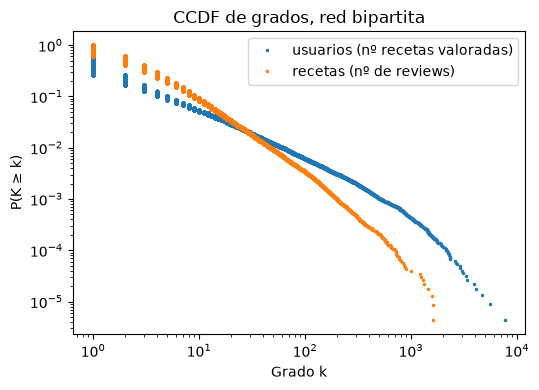

In [6]:
edges = inter.drop_duplicates(["user_id", "recipe_id"])[["user_id", "recipe_id", "rating", "review", "n_words", "date"]]
user_deg = edges.groupby("user_id").size()
rec_deg = edges.groupby("recipe_id").size()

SUMMARY["user_degree_median"] = float(user_deg.median())
SUMMARY["pct_users_with_1_review"] = round(100 * (user_deg == 1).mean(), 1)
SUMMARY["recipe_degree_median"] = float(rec_deg.median())
SUMMARY["max_user_degree"] = int(user_deg.max())
SUMMARY["max_recipe_degree"] = int(rec_deg.max())
SUMMARY["users_with_at_least_k"] = {k: int((user_deg >= k).sum()) for k in [5, 10, 20, 50, 100]}
SUMMARY["recipes_with_at_least_k"] = {k: int((rec_deg >= k).sum()) for k in [5, 10, 20, 50, 100]}
for k in ["user_degree_median", "pct_users_with_1_review", "recipe_degree_median",
          "max_user_degree", "max_recipe_degree", "users_with_at_least_k", "recipes_with_at_least_k"]:
    print(f"{k:28s} {SUMMARY[k]}")

fig, ax = plt.subplots(figsize=(5.5, 4))
ccdf(user_deg.values, "usuarios (nº recetas valoradas)", ax)
ccdf(rec_deg.values, "recetas (nº de reviews)", ax)
ax.set_xlabel("Grado k"); ax.set_ylabel("P(K ≥ k)"); ax.legend(); ax.set_title("CCDF de grados, red bipartita")
savefig("03_ccdf_bipartita")

La mayoría de usuarios valora 1 o 2 recetas: no aportan estructura. Nos quedamos con el **núcleo** de usuarios y recetas activos (k-core bipartito: cada usuario ≥ `KU` recetas y cada receta ≥ `KR` usuarios, aplicado iterativamente). La tabla muestra el tamaño para varios umbrales: **el curso recomienda de unos cientos a unos miles de nodos**.

In [7]:
def bipartite_core(df, ku, kr, max_iter=100):
    d = df
    for _ in range(max_iter):
        ud = d["user_id"].map(d["user_id"].value_counts())
        rd = d["recipe_id"].map(d["recipe_id"].value_counts())
        keep = (ud >= ku) & (rd >= kr)
        if keep.all():
            break
        d = d[keep]
    return d

rows = []
for ku in [10, 20, 50]:
    for kr in [5, 10, 20]:
        c = bipartite_core(edges, ku, kr)
        rows.append(dict(KU=ku, KR=kr, usuarios=c["user_id"].nunique(),
                         recetas=c["recipe_id"].nunique(), aristas=len(c)))
core_grid = pd.DataFrame(rows)
SUMMARY["core_grid"] = core_grid.to_dict("records")
core_grid

,KU,KR,usuarios,recetas,aristas
0,10,5,9409,37940,488104
1,10,10,7452,12911,311389
2,10,20,5437,3905,176140
3,20,5,4809,34064,410836
4,20,10,3477,10636,237320
5,20,20,2192,2640,109104
6,50,5,1760,27542,293542
7,50,10,1048,6693,127971
8,50,20,0,0,0


In [ ]:
# >>> Umbrales: por defecto se elige la fila de la tabla más cercana a TARGET_USERS.
#     Si prefieres otros, pon p. ej. KU, KR = 20, 10 debajo. <<<
TARGET_USERS = 3000
okg = core_grid[core_grid["usuarios"] > 0]
best_row = okg.iloc[(okg["usuarios"] - TARGET_USERS).abs().argmin()]
KU, KR = int(best_row["KU"]), int(best_row["KR"])
core = bipartite_core(edges, KU, KR).copy()
users = np.sort(core["user_id"].unique()); recs = np.sort(core["recipe_id"].unique())
u_idx = {u: i for i, u in enumerate(users)}; r_idx = {r: i for i, r in enumerate(recs)}
core["ui"] = core["user_id"].map(u_idx); core["ri"] = core["recipe_id"].map(r_idx)
nu, nr = len(users), len(recs)b
SUMMARY["chosen_core"] = dict(KU=KU, KR=KR, users=nu, recipes=nr, edges=len(core), pct_of_all_interactions=round(100 * len(core) / len(inter), 1))
print(SUMMARY["chosen_core"])

{'KU': 20, 'KR': 10, 'users': 3477, 'recipes': 10636, 'edges': 237320, 'pct_of_all_interactions': 21.0}


Solo elige de la tabla la fila más cercana a 3.000 usuarios, que es el tamaño que recomienda el curso. Es una decisión arbitraria. En el paper hay que justificarla y comprobar que los resultados se mantienen con otro umbral (por ejemplo, KU=10 y KR=20).

## 4. Red usuario–usuario: proyección, backbone y comunidades

Dos usuarios se conectan si han valorado las mismas recetas. Peso = nº de recetas en común. Esa proyección es casi completa (los usuarios muy activos comparten algo con todo el mundo), por lo que tenemos un hairball, y queremos extraer el **backbone con el disparity filter** (semana 4) en lugar de un umbral global (versión filtrada de la red con sus conexiones más importantes)

El backbone solo se queda con los enlaces importantes

In [9]:
def project_users(ui, ri, nu, nr):
    B = sparse.csr_matrix((np.ones(len(ui)), (ui, ri)), shape=(nu, nr))
    W = sparse.triu(B @ B.T, k=1).tocoo()
    return W.row, W.col, W.data, np.asarray(B.sum(axis=1)).ravel()

def disparity_filter(row, col, w, n, alpha):
    s = np.bincount(row, weights=w, minlength=n) + np.bincount(col, weights=w, minlength=n)
    k = np.bincount(row, minlength=n) + np.bincount(col, minlength=n)
    a_row = (1 - w / s[row]) ** (k[row] - 1)
    a_col = (1 - w / s[col]) ** (k[col] - 1)
    return (a_row < alpha) | (a_col < alpha)

row, col, w, udeg = project_users(core["ui"].values, core["ri"].values, nu, nr)
SUMMARY["projection_full"] = dict(edges=int(len(w)), density=round(2 * len(w) / (nu * (nu - 1)), 4),
                                  median_shared_recipes=float(np.median(w)))
print("Proyección completa:", SUMMARY["projection_full"])

bb_rows = []
for alpha in [0.01, 0.05, 0.1]:
    keep = disparity_filter(row, col, w, nu, alpha)
    G_tmp = nx.Graph(); G_tmp.add_nodes_from(range(nu))
    G_tmp.add_edges_from(zip(row[keep], col[keep]))
    gcc = max(nx.connected_components(G_tmp), key=len)
    bb_rows.append(dict(alpha=alpha, aristas=int(keep.sum()), densidad=round(2 * keep.sum() / (nu * (nu - 1)), 4),
                        pct_nodos_en_GCC=round(100 * len(gcc) / nu, 1)))
SUMMARY["backbone_grid"] = bb_rows
pd.DataFrame(bb_rows)

Proyección completa: {'edges': 2799026, 'density': 0.4632, 'median_shared_recipes': 1.0}


,alpha,aristas,densidad,pct_nodos_en_GCC
0,0.01,35503,0.0059,98.4
1,0.05,130905,0.0217,100.0
2,0.10,258455,0.0428,100.0


In [10]:
# >>> Elige alpha: pocas aristas pero que casi todos los nodos sigan en la componente gigante <<<
ALPHA = 0.05

def build_backbone(row, col, w, n, alpha):
    keep = disparity_filter(row, col, w, n, alpha)
    G = nx.Graph()
    G.add_weighted_edges_from(zip(row[keep].tolist(), col[keep].tolist(), w[keep].tolist()))
    return G.subgraph(max(nx.connected_components(G), key=len)).copy()

Gu = build_backbone(row, col, w, nu, ALPHA)
SUMMARY["user_backbone"] = dict(nodes=Gu.number_of_nodes(), edges=Gu.number_of_edges(),
                                density=round(nx.density(Gu), 4),
                                avg_clustering=round(nx.average_clustering(Gu), 3),
                                degree_assortativity=round(nx.degree_assortativity_coefficient(Gu), 3))
print(SUMMARY["user_backbone"])

{'nodes': 3477, 'edges': 130905, 'density': 0.0217, 'avg_clustering': 0.795, 'degree_assortativity': -0.353}


In [ ]:
def louvain_labels(G, seed):
    parts = nx.community.louvain_communities(G, weight="weight", seed=seed)
    Q = nx.community.modularity(G, parts, weight="weight")
    lab = {n: i for i, p in enumerate(sorted(parts, key=len, reverse=True)) for n in p}
    return parts, Q, lab

runs = [louvain_labels(Gu, s) for s in range(5)]
Qs = [r[1] for r in runs]
nodes = list(Gu.nodes())
nmis = [normalized_mutual_info_score([runs[i][2][n] for n in nodes], [runs[j][2][n] for n in nodes])
        for i in range(5) for j in range(i + 1, 5)]
best = int(np.argmax(Qs))
parts, Q_real, comm_of = runs[best]
sizes = sorted([len(p) for p in parts], reverse=True)
SUMMARY["louvain"] = dict(Q_runs=[round(q, 3) for q in Qs], n_communities_runs=[len(r[0]) for r in runs],
                          stability_NMI_mean=round(float(np.mean(nmis)), 3),
                          sizes_best=sizes[:10], n_comms_ge_30=sum(s >= 30 for s in sizes))
print(SUMMARY["louvain"])

#vemos que la estabilidad es baja (NMI es 0.512 between different seeds ->> communities change a lot depending on the seed)

{'Q_runs': [0.194, 0.2, 0.197, 0.2, 0.199], 'n_communities_runs': [4, 4, 3, 4, 4], 'stability_NMI_mean': 0.512, 'sizes_best': [2290, 694, 429, 64], 'n_comms_ge_30': 4}


### Modelo nulo de todo el pipeline

El curso pide comparar la Q real con Louvain sobre **redes barajadas que preservan grados**. Aquí barajamos la **red bipartita** (cada usuario conserva su nº de recetas y cada receta su nº de usuarios) y repetimos exactamente el mismo pipeline: proyección → backbone → Louvain. Para explorar bastan 5 barajados; para el paper, 20.

nulo 1/5: Q=0.058  (swaps hechos/arista=9.3, 17s)
nulo 2/5: Q=0.062  (swaps hechos/arista=9.3, 36s)
nulo 3/5: Q=0.062  (swaps hechos/arista=9.3, 53s)
nulo 4/5: Q=0.061  (swaps hechos/arista=9.3, 70s)
nulo 5/5: Q=0.058  (swaps hechos/arista=9.3, 87s)
{'Q_real': 0.2, 'Q_null_mean': 0.06, 'Q_null_std': 0.002, 'z': 88.7}


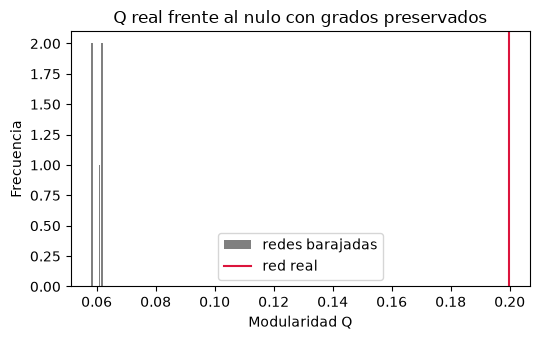

In [ ]:
def rewire_bipartite(ui, ri, swaps_per_edge, rng):
    ui = ui.copy(); ri = ri.copy(); m = len(ui)
    E = set(zip(ui.tolist(), ri.tolist()))
    n_try = swaps_per_edge * m
    A = rng.integers(m, size=n_try); Bx = rng.integers(m, size=n_try)
    done = 0
    for a, b in zip(A.tolist(), Bx.tolist()):
        u1, r1, u2, r2 = ui[a], ri[a], ui[b], ri[b]
        if u1 == u2 or r1 == r2 or (u1, r2) in E or (u2, r1) in E:
            continue
        E.discard((u1, r1)); E.discard((u2, r2)); E.add((u1, r2)); E.add((u2, r1))
        ri[a], ri[b] = r2, r1
        done += 1
    return ui, ri, done / m

N_NULL, SWAPS = 5, 10
Q_null = []
t0 = time.time()
for i in range(N_NULL):
    ui_n, ri_n, frac = rewire_bipartite(core["ui"].values, core["ri"].values, SWAPS, rng)
    rn, cn, wn, _ = project_users(ui_n, ri_n, nu, nr)
    Gn = build_backbone(rn, cn, wn, nu, ALPHA)
    Q_null.append(louvain_labels(Gn, SEED)[1])
    print(f"nulo {i+1}/{N_NULL}: Q={Q_null[-1]:.3f}  (swaps hechos/arista={frac:.1f}, {time.time()-t0:.0f}s)")
z = (Q_real - np.mean(Q_null)) / (np.std(Q_null) + 1e-12)
SUMMARY["modularity_null"] = dict(Q_real=round(Q_real, 3), Q_null_mean=round(float(np.mean(Q_null)), 3),
                                  Q_null_std=round(float(np.std(Q_null)), 3), z=round(float(z), 1))
print(SUMMARY["modularity_null"])

plt.figure(figsize=(5.5, 3.5))
plt.hist(Q_null, bins=10, color="grey", label="redes barajadas")
plt.axvline(Q_real, color="crimson", label="red real")
plt.xlabel("Modularidad Q"); plt.ylabel("Frecuencia"); plt.legend()
plt.title("Q real frente al nulo con grados preservados")
savefig("04_modularidad_vs_nulo")


#vemos que hay diferencia entre la modularidad real y lo que habría en el null model, lo que demuestra que las comunidades son reales, no un efecto de que algunos usuarios reseñen muchísimo. 
# Sin esta comparación, Q no demostraría nada.

👀 **Qué mirar:** si `Q_real` apenas supera a `Q_null`, las comunidades de usuarios **no son reales** y la Idea 1 se cae (o hay que replantearla). Si la supera con claridad y `stability_NMI_mean` es alta (> 0,7 aprox.), hay base.

### ¿Qué son esas comunidades? (gustos frente a época o actividad)
Para cada comunidad grande: qué etiquetas de receta están sobrerrepresentadas (lift), en qué año está activa y cuánto valoran sus usuarios. **Si se distinguen sobre todo por el año, son "generaciones", no gustos.**

In [ ]:
#Para cada comunidad muestra las etiquetas de receta sobrerrepresentadas, el año mediano y la nota media.

core["comm"] = core["ui"].map(comm_of)
cc = core.dropna(subset=["comm"]).copy(); cc["comm"] = cc["comm"].astype(int)
big = [c for c, n in cc.groupby("comm")["ui"].nunique().items() if n >= 30][:8]
rec_tags = recipes.set_index("id")["tags"]
overall = Counter(t for r in cc["recipe_id"] for t in rec_tags.get(r, []))
n_all = len(cc)
profile = {}
for c in big:
    sub = cc[cc["comm"] == c]
    cnt = Counter(t for r in sub["recipe_id"] for t in rec_tags.get(r, []))
    lift = {t: (cnt[t] / len(sub)) / (overall[t] / n_all) for t in cnt if cnt[t] >= 20}
    top = sorted(lift, key=lift.get, reverse=True)[:8]
    profile[c] = dict(users=int(sub["ui"].nunique()), median_year=int(sub["date"].dt.year.median()),
                      mean_rating=round(float(sub["rating"].mean()), 2),
                      top_tags=[f"{t} ({lift[t]:.1f}x)" for t in top])
    print(f"Comunidad {c}: {profile[c]}")
SUMMARY["community_profiles"] = profile

Comunidad 0: {'users': 2290, 'median_year': 2008, 'mean_rating': 4.59, 'top_tags': ['elk (1.6x)', 'moose (1.6x)', 'meatloaf (1.6x)', 'chocolate-chip-cookies (1.5x)', 'manicotti (1.5x)', 'baking (1.4x)', 'cake-fillings-and-frostings (1.4x)', 'deer (1.4x)']}
Comunidad 1: {'users': 694, 'median_year': 2006, 'mean_rating': 4.67, 'top_tags': ['bok-choys (1.9x)', 'trout (1.9x)', 'hunan (1.6x)', 'gelatin (1.6x)', 'czech (1.5x)', 'quebec (1.5x)', 'halibut (1.5x)', 'jewish-ashkenazi (1.5x)']}
Comunidad 2: {'users': 429, 'median_year': 2008, 'mean_rating': 4.77, 'top_tags': ['polynesian (3.6x)', 'non-alcoholic (3.5x)', 'iraqi (3.5x)', 'saudi-arabian (3.4x)', 'nut-free (3.3x)', 'from-scratch (3.1x)', 'brazilian (2.8x)', 'south-african (2.8x)']}
Comunidad 3: {'users': 64, 'median_year': 2008, 'mean_rating': 4.89, 'top_tags': ['stuffings-dressings (9.2x)', ' (8.3x)', 'wedding (6.6x)', 'halloween (6.3x)', 'steam (6.0x)', 'pork-ribs (4.8x)', 'scones (3.7x)', 'crab (3.5x)']}


## 5. Prueba rápida — Idea 1: ¿el lenguaje de las reviews delata la comunidad?

Clasificador TF-IDF + regresión logística que intenta adivinar la comunidad del autor a partir del texto de la review. Se compara con **etiquetas barajadas** (nulo). **Ojo, confusión:** si las comunidades se separan por tipo de receta, las reviews hablarán de esas recetas ("cake", "chicken"). La segunda prueba quita ese efecto usando solo recetas valoradas por varias comunidades.

In [ ]:
#¿el texto delata la comunidad? Un clasificador intenta adivinar la comunidad a partir de la review. Acierta un 53 % frente al 25 % del azar, y lo mismo con recetas compartidas.

def text_signal(df, label_col, n_per_class=1500, seed=SEED):
    df = df[df["n_words"] >= 5]
    df = df.sample(frac=1, random_state=seed).groupby(label_col).head(n_per_class)
    X = TfidfVectorizer(stop_words="english", min_df=5, max_features=20000).fit_transform(df["review"])
    y = df[label_col].values
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    clf = LogisticRegression(max_iter=2000)
    acc = cross_val_score(clf, X, y, cv=cv).mean()
    acc_null = cross_val_score(clf, X, np.random.default_rng(seed).permutation(y), cv=cv).mean()
    return round(float(acc), 3), round(float(acc_null), 3), round(1 / len(set(y)), 3), len(df)

top_comms = big[:4]
d1 = cc[cc["comm"].isin(top_comms)]
acc, acc_null, chance, n = text_signal(d1, "comm")
print(f"Todas las reviews: accuracy={acc}  nulo barajado={acc_null}  azar={chance}  (n={n})")

# Control: solo recetas valoradas por ≥2 de esas comunidades (mismo plato, distinta comunidad)
shared_recs = d1.groupby("recipe_id")["comm"].nunique()
d2 = d1[d1["recipe_id"].isin(shared_recs[shared_recs >= 2].index)]
acc2, acc2_null, chance2, n2 = text_signal(d2, "comm")
print(f"Solo recetas compartidas: accuracy={acc2}  nulo={acc2_null}  azar={chance2}  (n={n2})")
SUMMARY["idea1_text_signal"] = dict(all=dict(acc=acc, null=acc_null, chance=chance, n=n),
                                    shared_recipes=dict(acc=acc2, null=acc2_null, chance=chance2, n=n2))

Todas las reviews: accuracy=0.536  nulo barajado=0.247  azar=0.25  (n=6000)
Solo recetas compartidas: accuracy=0.533  nulo=0.247  azar=0.25  (n=6000)


In [ ]:
# Palabras más distintivas por comunidad (log-ratio de frecuencias suavizado)
cv_ = CountVectorizer(stop_words="english", min_df=20, max_features=20000)
sub = d1[d1["n_words"] >= 5].sample(frac=1, random_state=SEED).groupby("comm").head(3000)
X = cv_.fit_transform(sub["review"]); vocab = np.array(cv_.get_feature_names_out())
tot = np.asarray(X.sum(0)).ravel()
for c in top_comms:
    m = (sub["comm"] == c).values
    a = np.asarray(X[m].sum(0)).ravel(); b = tot - a
    lr = np.log((a + 1) / (a.sum() + len(vocab))) - np.log((b + 1) / (b.sum() + len(vocab)))
    print(f"Comunidad {c}: {', '.join(vocab[np.argsort(-lr)[:15]])}")

Comunidad 0: cupcakes, pesto, layers, whites, cheap, okay, shortening, oats, rated, choc, chip, cooled, sloppy, ranch, candy
Comunidad 1: roxygirl, jello, favourite, carb, sherry, mark, planning, legs, recommended, shaped, spectacular, girl, incredible, roasting, wet
Comunidad 2: tag, zwt6, tagged, 2011, zwt, zwt5, 2010, tour, prmr, zwt4, pac, game, swap, nz, aus
Comunidad 3: sushi, linda, tony, baskets, dug, cookout, cindy, sprinkles, anytime, mike, loaded, grandchildren, hrs, gf, easter


In [ ]:
#Celda 15, palabras distintivas. La comunidad 2 da zwt, zwt5, zwt6, tag, tagged, tour, game, swap, pac: jerga de juegos.
#Junto con las etiquetas de regiones del mundo de la celda 13, sugiere que es la comunidad de la Zaar World Tour. Las comunidades 1 y 3 dan nombres de personas (roxygirl, linda, tony).

👀 **Qué mirar:** si la accuracy supera claramente al nulo **también en recetas compartidas**, hay una señal lingüística propia de las comunidades (estilo, no solo tema): la Idea 1 es fuerte. Si solo funciona con todas las reviews, el lenguaje refleja *qué cocinan*, no *cómo hablan*; también es un resultado, pero hay que contarlo así.

## 6. Prueba rápida — Idea 2: ¿ingredientes parecidos implican opiniones parecidas?
Para pares aleatorios de recetas del núcleo: Jaccard de ingredientes frente a coseno TF-IDF de sus reviews. Se repite **quitando los nombres de ingredientes del texto**, para evitar circularidad.

In [16]:
ing = recipes.set_index("id")["ingredients"].apply(lambda l: set(x.lower() for x in l))
rev_by_rec = core[core["n_words"] > 0].groupby("recipe_id")["review"].apply(lambda s: " ".join(s.tolist()[:50]))
rids = [r for r in rev_by_rec.index if r in ing.index]
ing_words = sorted({wd for s in ing.loc[rids] for x in s for wd in x.split()})

def pair_corr(remove_ingredient_words):
    stop = list(TfidfVectorizer(stop_words="english").get_stop_words())
    if remove_ingredient_words:
        stop += ing_words
    V = TfidfVectorizer(stop_words=stop, min_df=5, max_features=30000).fit_transform(rev_by_rec.loc[rids])
    n = len(rids); i = rng.integers(n, size=20000); j = rng.integers(n, size=20000)
    ok = i != j; i, j = i[ok], j[ok]
    cos = np.asarray(V[i].multiply(V[j]).sum(1)).ravel()
    jac = np.array([len(ing[rids[a]] & ing[rids[b]]) / max(1, len(ing[rids[a]] | ing[rids[b]])) for a, b in zip(i, j)])
    return round(float(spearmanr(jac, cos)[0]), 3)

SUMMARY["idea2_spearman"] = dict(with_ingredient_words=pair_corr(False), without_ingredient_words=pair_corr(True))
print(SUMMARY["idea2_spearman"])

{'with_ingredient_words': 0.203, 'without_ingredient_words': 0.104}


👀 **Qué mirar:** si la correlación cae mucho al quitar los ingredientes, la relación era sobre todo circular (las reviews nombran los ingredientes). Además, esta idea usa poca "network science": la red sería casi decorativa.

## 7. Prueba rápida — Idea 3: ¿las recetas populares conectan comunidades?
Para cada receta: su grado (popularidad) y la **entropía** de las comunidades de sus usuarios (alta = la valoran usuarios de comunidades distintas). La betweenness en la bipartita se aproxima con muestreo. La pregunta interesante es si conectan **más de lo que predice su popularidad**.

betweenness en 77s
{'spearman_degree_vs_entropy': 0.167, 'spearman_degree_vs_betweenness': 0.781}


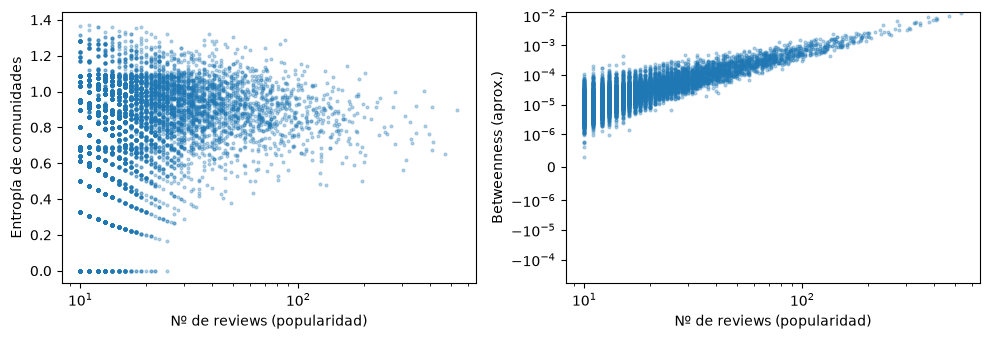

In [17]:
r_deg = cc.groupby("recipe_id").size()
def entropy(s):
    p = s.value_counts(normalize=True).values
    return float(-(p * np.log(p)).sum())
r_ent = cc.groupby("recipe_id")["comm"].apply(entropy)

Gb = nx.Graph()
Gb.add_edges_from(zip(("u" + core["user_id"].astype(str)).tolist(), ("r" + core["recipe_id"].astype(str)).tolist()))
t0 = time.time()
btw = nx.betweenness_centrality(Gb, k=min(200, Gb.number_of_nodes()), seed=SEED)
print(f"betweenness en {time.time()-t0:.0f}s")
r_btw = pd.Series({int(k[1:]): v for k, v in btw.items() if k.startswith("r")})
dfr = pd.DataFrame(dict(deg=r_deg, ent=r_ent, btw=r_btw)).dropna()
SUMMARY["idea3"] = dict(spearman_degree_vs_entropy=round(float(spearmanr(dfr.deg, dfr.ent)[0]), 3),
                        spearman_degree_vs_betweenness=round(float(spearmanr(dfr.deg, dfr.btw)[0]), 3))
print(SUMMARY["idea3"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(dfr.deg, dfr.ent, s=4, alpha=.3); axes[0].set_xscale("log")
axes[0].set_xlabel("Nº de reviews (popularidad)"); axes[0].set_ylabel("Entropía de comunidades")
axes[1].scatter(dfr.deg, dfr.btw, s=4, alpha=.3); axes[1].set_xscale("log"); axes[1].set_yscale("symlog", linthresh=1e-6)
axes[1].set_xlabel("Nº de reviews (popularidad)"); axes[1].set_ylabel("Betweenness (aprox.)")
savefig("05_idea3_popularidad_vs_puente")

👀 **Qué mirar:** si la betweenness y el grado tienen una correlación de Spearman de ~0,9, "las populares son puentes" es casi trivial. Lo interesante serían los **residuos**: recetas que conectan más (o menos) de lo esperado por su popularidad. Para el paper, el nulo es la bipartita barajada de la sección 4.

## 8. Resumen — copia esto y pégamelo

In [18]:
print(json.dumps(SUMMARY, indent=1, default=str))

{
 "n_recipes": 231637,
 "n_users": 226570,
 "n_interactions": 1132367,
 "n_recipes_with_any_interaction": 231637,
 "interactions_recipe_missing": 0,
 "duplicate_user_recipe_pairs": 0,
 "date_range": [
  "2000-01-25",
  "2018-12-20"
 ],
 "rating_share": {
  "0": 0.054,
  "1": 0.011,
  "2": 0.012,
  "3": 0.036,
  "4": 0.165,
  "5": 0.721
 },
 "pct_reviews_with_text": 99.98,
 "review_words_percentiles": {
  "10": 16,
  "25": 27,
  "50": 44,
  "75": 67,
  "90": 96,
  "99": 182
 },
 "pct_reviews_under_10_words": 4.53,
 "total_review_words_millions": 58.9,
 "user_degree_median": 1.0,
 "pct_users_with_1_review": 73.4,
 "recipe_degree_median": 2.0,
 "max_user_degree": 7671,
 "max_recipe_degree": 1613,
 "users_with_at_least_k": {
  "5": 23086,
  "10": 12486,
  "20": 6687,
  "50": 2755,
  "100": 1382
 },
 "recipes_with_at_least_k": {
  "5": 53593,
  "10": 21399,
  "20": 7982,
  "50": 2164,
  "100": 787
 },
 "core_grid": [
  {
   "KU": 10,
   "KR": 5,
   "usuarios": 9409,
   "recetas": 37940,
  